<a href="https://colab.research.google.com/github/jose-esquivel-dev/Analitica_de_Datos/blob/main/U2/Practica_4/AD_U2_Practica4_Equipo3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

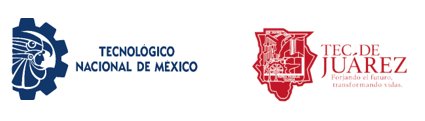

#**INSTITUTO TECNOLOGICO DE CIUDAD JUAREZ**
**Ciencia y analítica de datos**

MODELOS DE APRENDIZAJE

**ACTIVIDAD**: *Regresión logística*
| Integrante | No. de control |
|---|---|
| María Fernanda Delgado Ramírez | 23111480 |
| Mia Llanas Hernández | 22111513 |
| José Enrique Esquivel Torres | 23110182 |

---

In [34]:
# Montar Google Drive (solo aplica en Google Colab)
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [35]:
import os

# Ruta del archivo data.csv. Cada integrante la ajusta a la ubicación en su Drive.
RUTA_CSV = "/content/drive/MyDrive/Colab Notebooks/Analisis/data.csv" # Delgado
# RUTA_CSV = "/content/drive/MyDrive/Análitica de Datos /data.csv"      # Llanas
# RUTA_CSV = "/content/drive/MyDrive/Colab Notebooks/Analitica_De_Datos/U2/Ejemplos/data.csv" # Esquivel

In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Librerías para preprocesamiento e ing de características
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import MinMaxScaler, OneHotEncoder,StandardScaler, OrdinalEncoder,FunctionTransformer

# Librerías para la canalización
from sklearn.compose import ColumnTransformer, make_column_selector
from sklearn.pipeline import make_pipeline

# Librerías para la regresión
from sklearn.linear_model import LinearRegression
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.metrics import mean_squared_error, mean_squared_error, r2_score, confusion_matrix, precision_score,recall_score,accuracy_score
from sklearn.decomposition import PCA

from sklearn.preprocessing import PolynomialFeatures

---
## **Explica brevemente el uso de las librerias del segmento de codigo anterior, haciendo uso de la siguiente tabla</font>**

---

| Librería | Explicación |
|----------|-------------|
|**import pandas as pd**| Manipulación y análisis de datos mediante DataFrames (tablas): permite cargar, limpiar, filtrar y transformar los datos. |
|**import numpy as np**| Permite trabajar con arreglos numéricos y realizar operaciones matemáticas de forma eficiente; es la base de otras librerías. |
|**import matplotlib.pyplot as plt**| Permite crear gráficas como histogramas, diagramas de dispersión, de líneas y de caja para visualizar los datos y los resultados del modelo. |
|**import seaborn as sns** | Funciona sobre matplotlib y facilita crear visualizaciones estadísticas atractivas, como mapas de calor o distribuciones, con menos código. |
|**from sklearn.impute import SimpleImputer** | Rellena los valores faltantes (NaN) con un estadístico como la media, la mediana, el valor más frecuente o una constante. |
|**from sklearn.preprocessing import MinMaxScaler** | Reescala las variables numéricas a un rango fijo, normalmente entre 0 y 1, para que ninguna domine por su magnitud. |
|**from sklearn.preprocessing import OneHotEncoder** | Convierte variables categóricas sin orden en columnas binarias (ceros y unos), una por cada categoría. |
|**from sklearn.preprocessing import StandardScaler** | Estandariza las variables numéricas restando la media y dividiendo entre la desviación estándar, de modo que queden con media 0 y desviación estándar 1. |
|**from sklearn.preprocessing import OrdinalEncoder** | Convierte variables categóricas que tienen un orden natural en números enteros (0, 1, 2…) que conservan ese orden. |
|**from sklearn.preprocessing import FunctionTransformer** | Permite incluir una función propia (por ejemplo logaritmo o raíz cuadrada) como un paso dentro del flujo de preprocesamiento. |
|**from sklearn.compose import ColumnTransformer** | Aplica distintos procesos a distintos grupos de columnas, por ejemplo uno para las numéricas y otro para las categóricas. |
|**from sklearn.compose import make_column_selector** | Selecciona columnas de forma automática según su tipo de dato, sin tener que escribir sus nombres manualmente. |
|**from sklearn.pipeline import make_pipeline** | Encadena el preprocesamiento y el modelo en un solo flujo, de modo que se apliquen las mismas transformaciones a los datos de entrenamiento y de prueba, evitando errores como la fuga de datos (*data leakage*). |
|**from sklearn.linear_model import LinearRegression** | Modelo de regresión lineal: predice un valor numérico continuo buscando la recta (combinación lineal de las variables de entrada) que mejor se ajusta a los datos. |
|**from sklearn.linear_model import LogisticRegression** | Modelo de clasificación que estima la probabilidad de que un dato pertenezca a una clase usando la función sigmoide; a pesar de su nombre, no se usa para predecir valores continuos. |
|**from sklearn.metrics import mean_squared_error** | Calcula el error cuadrático medio: el promedio de los errores al cuadrado entre los valores reales y los predichos en un problema de regresión. |
|**from sklearn.metrics import r2_score** | Coeficiente de determinación: indica qué proporción de la variación de la variable objetivo logra explicar el modelo (1 es un ajuste perfecto). |
|**from sklearn.metrics import confusion_matrix** | Genera una tabla que compara las clases reales con las predichas y muestra verdaderos positivos, verdaderos negativos, falsos positivos y falsos negativos. |
|**from sklearn.metrics import precision_score** | Mide qué proporción de las predicciones positivas del modelo fueron realmente correctas. |
|**from sklearn.metrics import recall_score** | Mide qué proporción de los casos positivos reales fue identificada por el modelo (sensibilidad). |
|**from sklearn.metrics import accuracy_score** | Mide la proporción de predicciones correctas sobre el total de predicciones realizadas (exactitud global). |
|**from sklearn.decomposition import PCA** | Análisis de Componentes Principales: reduce el número de variables proyectando los datos en componentes no correlacionados que conservan la mayor parte de la información original. |
|**from sklearn.preprocessing import PolynomialFeatures** | Genera variables elevadas a una potencia y combinaciones entre variables, lo que permite que un modelo lineal capture relaciones no lineales. |

---

In [6]:
#lectura del .csv con pandas
data_df = pd.read_csv(RUTA_CSV)
data_df

,id,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,...,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst
0,842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.30010,0.14710,...,25.380,17.33,184.60,2019.0,0.16220,0.66560,0.7119,0.2654,0.4601,0.11890
1,842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.08690,0.07017,...,24.990,23.41,158.80,1956.0,0.12380,0.18660,0.2416,0.1860,0.2750,0.08902
2,84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.19740,0.12790,...,23.570,25.53,152.50,1709.0,0.14440,0.42450,0.4504,0.2430,0.3613,0.08758
3,84348301,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.24140,0.10520,...,14.910,26.50,98.87,567.7,0.20980,0.86630,0.6869,0.2575,0.6638,0.17300
4,84358402,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.19800,0.10430,...,22.540,16.67,152.20,1575.0,0.13740,0.20500,0.4000,0.1625,0.2364,0.07678
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
564,926424,M,21.56,22.39,142.00,1479.0,0.11100,0.11590,0.24390,0.13890,...,25.450,26.40,166.10,2027.0,0.14100,0.21130,0.4107,0.2216,0.2060,0.07115
565,926682,M,20.13,28.25,131.20,1261.0,0.09780,0.10340,0.14400,0.09791,...,23.690,38.25,155.00,1731.0,0.11660,0.19220,0.3215,0.1628,0.2572,0.06637
566,926954,M,16.60,28.08,108.30,858.1,0.08455,0.10230,0.09251,0.05302,...,18.980,34.12,126.70,1124.0,0.11390,0.30940,0.3403,0.1418,0.2218,0.07820
567,927241,M,20.60,29.33,140.10,1265.0,0.11780,0.27700,0.35140,0.15200,...,25.740,39.42,184.60,1821.0,0.16500,0.86810,0.9387,0.2650,0.4087,0.12400


# **Parte 1**. EDA

Haz que el `id` sea el índice del dataframe y efectúa una exploración inicial de los datos a través de:

In [7]:
#utilice funcion .set_index()
#Guarde los cambios con inplace=True

#-----------------------------------------------------
#Escriba su codigo
data_df.set_index('id', inplace=True)
#-----------------------------------------------------
data_df

,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,symmetry_mean,...,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst
id,,,,,,,,,,,,,,,,,,,,,
842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.30010,0.14710,0.2419,...,25.380,17.33,184.60,2019.0,0.16220,0.66560,0.7119,0.2654,0.4601,0.11890
842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.08690,0.07017,0.1812,...,24.990,23.41,158.80,1956.0,0.12380,0.18660,0.2416,0.1860,0.2750,0.08902
84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.19740,0.12790,0.2069,...,23.570,25.53,152.50,1709.0,0.14440,0.42450,0.4504,0.2430,0.3613,0.08758
84348301,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.24140,0.10520,0.2597,...,14.910,26.50,98.87,567.7,0.20980,0.86630,0.6869,0.2575,0.6638,0.17300
84358402,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.19800,0.10430,0.1809,...,22.540,16.67,152.20,1575.0,0.13740,0.20500,0.4000,0.1625,0.2364,0.07678
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
926424,M,21.56,22.39,142.00,1479.0,0.11100,0.11590,0.24390,0.13890,0.1726,...,25.450,26.40,166.10,2027.0,0.14100,0.21130,0.4107,0.2216,0.2060,0.07115
926682,M,20.13,28.25,131.20,1261.0,0.09780,0.10340,0.14400,0.09791,0.1752,...,23.690,38.25,155.00,1731.0,0.11660,0.19220,0.3215,0.1628,0.2572,0.06637
926954,M,16.60,28.08,108.30,858.1,0.08455,0.10230,0.09251,0.05302,0.1590,...,18.980,34.12,126.70,1124.0,0.11390,0.30940,0.3403,0.1418,0.2218,0.07820


Se manda `id` como índice del DataFrame para que no se trate como una variable más (es solo un identificador, no una característica del tumor) y cada fila quede identificada por su `id`.

In [8]:
#Desglose de todas las columnas del data frame
data_df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 569 entries, 842302 to 92751
Data columns (total 31 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   diagnosis                569 non-null    object 
 1   radius_mean              569 non-null    float64
 2   texture_mean             569 non-null    float64
 3   perimeter_mean           569 non-null    float64
 4   area_mean                569 non-null    float64
 5   smoothness_mean          569 non-null    float64
 6   compactness_mean         569 non-null    float64
 7   concavity_mean           569 non-null    float64
 8   concave points_mean      569 non-null    float64
 9   symmetry_mean            569 non-null    float64
 10  fractal_dimension_mean   569 non-null    float64
 11  radius_se                569 non-null    float64
 12  texture_se               569 non-null    float64
 13  perimeter_se             569 non-null    float64
 14  area_se                 

Con `.info()` se obtiene el listado de todas las columnas con su tipo de dato y la cantidad de valores no nulos. Como se ve, casi todas son de tipo `float64` y solo una es de tipo texto (`object`): `diagnosis`.

1a) Estadísticas descriptivas para todas las variables del dataframe.

In [9]:
#.describe para variables Numericas
#-----------------------------------------------------
data_df.describe(include='number').T
#-----------------------------------------------------

,count,mean,std,min,25%,50%,75%,max
radius_mean,569.0,14.127292,3.524049,6.981000,11.700000,13.370000,15.780000,28.11000
texture_mean,569.0,19.289649,4.301036,9.710000,16.170000,18.840000,21.800000,39.28000
perimeter_mean,569.0,91.969033,24.298981,43.790000,75.170000,86.240000,104.100000,188.50000
area_mean,569.0,654.889104,351.914129,143.500000,420.300000,551.100000,782.700000,2501.00000
smoothness_mean,569.0,0.096360,0.014064,0.052630,0.086370,0.095870,0.105300,0.16340
compactness_mean,569.0,0.104341,0.052813,0.019380,0.064920,0.092630,0.130400,0.34540
concavity_mean,569.0,0.088799,0.079720,0.000000,0.029560,0.061540,0.130700,0.42680
concave points_mean,569.0,0.048919,0.038803,0.000000,0.020310,0.033500,0.074000,0.20120
symmetry_mean,569.0,0.181162,0.027414,0.106000,0.161900,0.179200,0.195700,0.30400
fractal_dimension_mean,569.0,0.062798,0.007060,0.049960,0.057700,0.061540,0.066120,0.09744


Para las variables numéricas, `describe()` muestra la cantidad de datos, el promedio, la desviación estándar, el valor mínimo, los cuartiles y el valor máximo de cada columna. La desviación estándar indica qué tan separados están los datos del promedio. Los cuartiles dividen los datos ordenados en cuatro partes iguales y el cuartil del 50% corresponde a la mediana. Se usa `include='number'` para considerar solo las variables numéricas y `.T` para transponer la tabla (cambiar columnas por filas), lo que facilita leerla con 30 variables.

In [10]:
#.describe() para variable categoricas
#-----------------------------------------------------
# exclude='number' deja solo las variables NO numericas (object / category / bool)
data_df.describe(exclude='number')
#-----------------------------------------------------

,diagnosis
count,569
unique,2
top,B
freq,357


Para las variables categóricas se muestra la cantidad de datos, el número de categorías distintas (`unique`), la categoría que más se repite (`top`) y cuántas veces aparece (`freq`). Esta información permite conocer cómo se distribuye la variable `diagnosis`. Aquí se usa `exclude='number'` para quedarse con todo lo que no es numérico (equivale a pedir `object`, `category` y `bool`).

1b) Valores únicos por variable para identificar posibles variables categóricas.

Primero se crean dos listas. La lista `num_cols` guarda los nombres de las columnas numéricas y la lista `cat_cols` guarda los nombres de las columnas que no son numéricas.

In [11]:
# Se hace una lista de variables numéricas y otra de categóricas.
#-----------------------------------------------------
num_cols = data_df.select_dtypes(include=np.number).columns.tolist() #para variables numericas
cat_cols = data_df.select_dtypes(exclude=np.number).columns.tolist() #para variables Categoricas
#-----------------------------------------------------

Después se usa `nunique()` para contar los valores distintos de cada columna. Una variable con muy pocos valores únicos (como `diagnosis`, con 2) es candidata a ser categórica.

In [12]:
# Cantidad de valores unicos por variable
data_df.nunique()

,0
diagnosis,2
radius_mean,456
texture_mean,479
perimeter_mean,522
area_mean,539
smoothness_mean,474
compactness_mean,537
concavity_mean,537
concave points_mean,542
symmetry_mean,432


Por último se recorre cada variable categórica con un ciclo `for` y se usa `value_counts()` para contar cuántas veces aparece cada categoría. En este conjunto de datos solo hay dos categorías: **B** (benigno) y **M** (maligno).

In [13]:
# Recuento de cada categoría única en las variables categóricas
for col in cat_cols:
    print(f"--- {col} ---")
    print(data_df[col].value_counts(), "\n")

--- diagnosis ---
diagnosis
B    357
M    212
Name: count, dtype: int64 



Como en este caso solo hay una variable categórica, existe una segunda forma de obtener el mismo recuento: llamar directamente a `value_counts()` sobre la columna `diagnosis`.

In [14]:
# Forma #2: recuento directo de la única variable categórica
data_df['diagnosis'].value_counts()

,count
diagnosis,
B,357
M,212


1c) Búsqueda de valores faltantes.

In [15]:
#Explica cada linea de codigo

# Muestra un titulo antes de los resultados
print('Número valores faltantes: ')

# Recorre una por una todas las columnas del DataFrame
for col in data_df.columns:

  # isna() marca con True cada dato faltante y con False cada dato presente.
  # sum() cuenta los True, porque Python los toma como 1. El resultado es la cantidad de datos faltantes.
  valor=sum(data_df[col].isna())

  # mean() de los True y False da la proporción de datos faltantes entre 0 y 1.
  # Al multiplicar por 100 se obtiene el porcentaje.
  porcentaje=data_df[col].isna().mean()*100

  # Imprime una línea por columna. Cada {} se llena en orden con col, valor y porcentaje.
  print('{}:{}: porcentaje :{}'.format(col,valor,porcentaje))

Número valores faltantes: 
diagnosis:0: porcentaje :0.0
radius_mean:0: porcentaje :0.0
texture_mean:0: porcentaje :0.0
perimeter_mean:0: porcentaje :0.0
area_mean:0: porcentaje :0.0
smoothness_mean:0: porcentaje :0.0
compactness_mean:0: porcentaje :0.0
concavity_mean:0: porcentaje :0.0
concave points_mean:0: porcentaje :0.0
symmetry_mean:0: porcentaje :0.0
fractal_dimension_mean:0: porcentaje :0.0
radius_se:0: porcentaje :0.0
texture_se:0: porcentaje :0.0
perimeter_se:0: porcentaje :0.0
area_se:0: porcentaje :0.0
smoothness_se:0: porcentaje :0.0
compactness_se:0: porcentaje :0.0
concavity_se:0: porcentaje :0.0
concave points_se:0: porcentaje :0.0
symmetry_se:0: porcentaje :0.0
fractal_dimension_se:0: porcentaje :0.0
radius_worst:0: porcentaje :0.0
texture_worst:0: porcentaje :0.0
perimeter_worst:0: porcentaje :0.0
area_worst:0: porcentaje :0.0
smoothness_worst:0: porcentaje :0.0
compactness_worst:0: porcentaje :0.0
concavity_worst:0: porcentaje :0.0
concave points_worst:0: porcentaje :

En esta sección se buscan valores faltantes en el conjunto de datos. Un valor faltante es una casilla vacía, es decir, un dato que no se registró. Es importante revisarlos antes de entrenar un modelo, porque muchos algoritmos no funcionan si hay datos vacíos.

El código recorre cada columna del `DataFrame` y utiliza `isna()` para marcar los datos faltantes. Después cuenta cuántos hay en cada columna y calcula qué porcentaje representan del total de filas. Al final imprime una línea por columna con su nombre, la cantidad de datos faltantes y el porcentaje.

Con este resultado se observa que **ninguna columna tiene valores faltantes** (todas muestran 0 y un porcentaje de `0.0`), por lo tanto los datos están completos y no es necesario rellenar ni eliminar registros antes de continuar con el análisis.

1d) Diagrama de barras para determinar la frecuencia de los diagnósticos (cantidad de observaciones con resultado benigno y maligno)

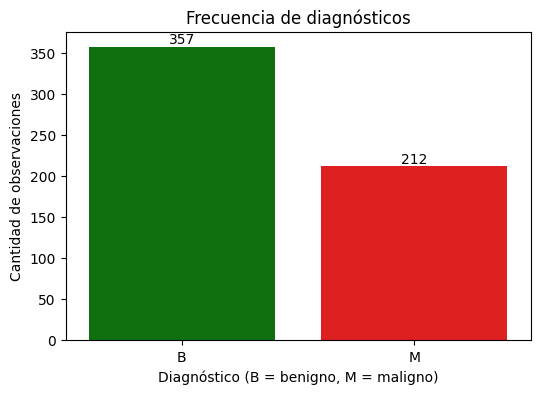

In [16]:
#utilice sns.countplot()
#-----------------------------------------------------
plt.figure(figsize=(6,4))

# Benigno (B) en verde y maligno (M) en rojo
ax = sns.countplot(data=data_df, x='diagnosis', hue='diagnosis',
                   order=['B','M'], palette={'B':'green','M':'red'}, legend=False)

# Escribe la cantidad de casos encima de cada barra
for container in ax.containers:
    ax.bar_label(container)

ax.set_title('Frecuencia de diagnósticos')
ax.set_xlabel('Diagnóstico (B = benigno, M = maligno)')
ax.set_ylabel('Cantidad de observaciones')
plt.show()
#-----------------------------------------------------

En esta sección se grafica cuántas observaciones hay de cada diagnóstico. La variable `diagnosis` tiene dos categorías: la letra **B** representa un resultado benigno y la letra **M** uno maligno.

Para esto se usa `sns.countplot()`, que cuenta cuántas veces aparece cada categoría y dibuja una barra para cada una. La altura de la barra indica la cantidad de observaciones y los números sobre las barras muestran esa cantidad de forma exacta.

Se observa que hay más casos benignos (357, aprox. 63%) que malignos (212, aprox. 37%). Las clases no están perfectamente balanceadas, por lo que más adelante conviene evaluar el modelo no solo con la exactitud (*accuracy*), sino también con métricas como *precision* y *recall*.

2. Como hay tres valores relacionados con la misma característica (`mean`, `se` y `worst`) es muy probable que exista multicolinealidad en el conjunto.

La multicolinealidad en regresión es una condición que ocurre cuando algunas variables predictoras están fuertemente correlacionadas entre sí, de tal manera que si se incluyen simultáneamente en un modelo, impiden explicar de manera correcta el efecto que cada una tiene sobre la variable respuesta. Existen muchas formas de analizar si hay colinealidad en los modelos, una de ellas es el alto coeficiente de correlación entre variables.

Para observar este efecto, elabora un mapa de calor que cuantifique la correlación de las variables numéricas en el dataframe.

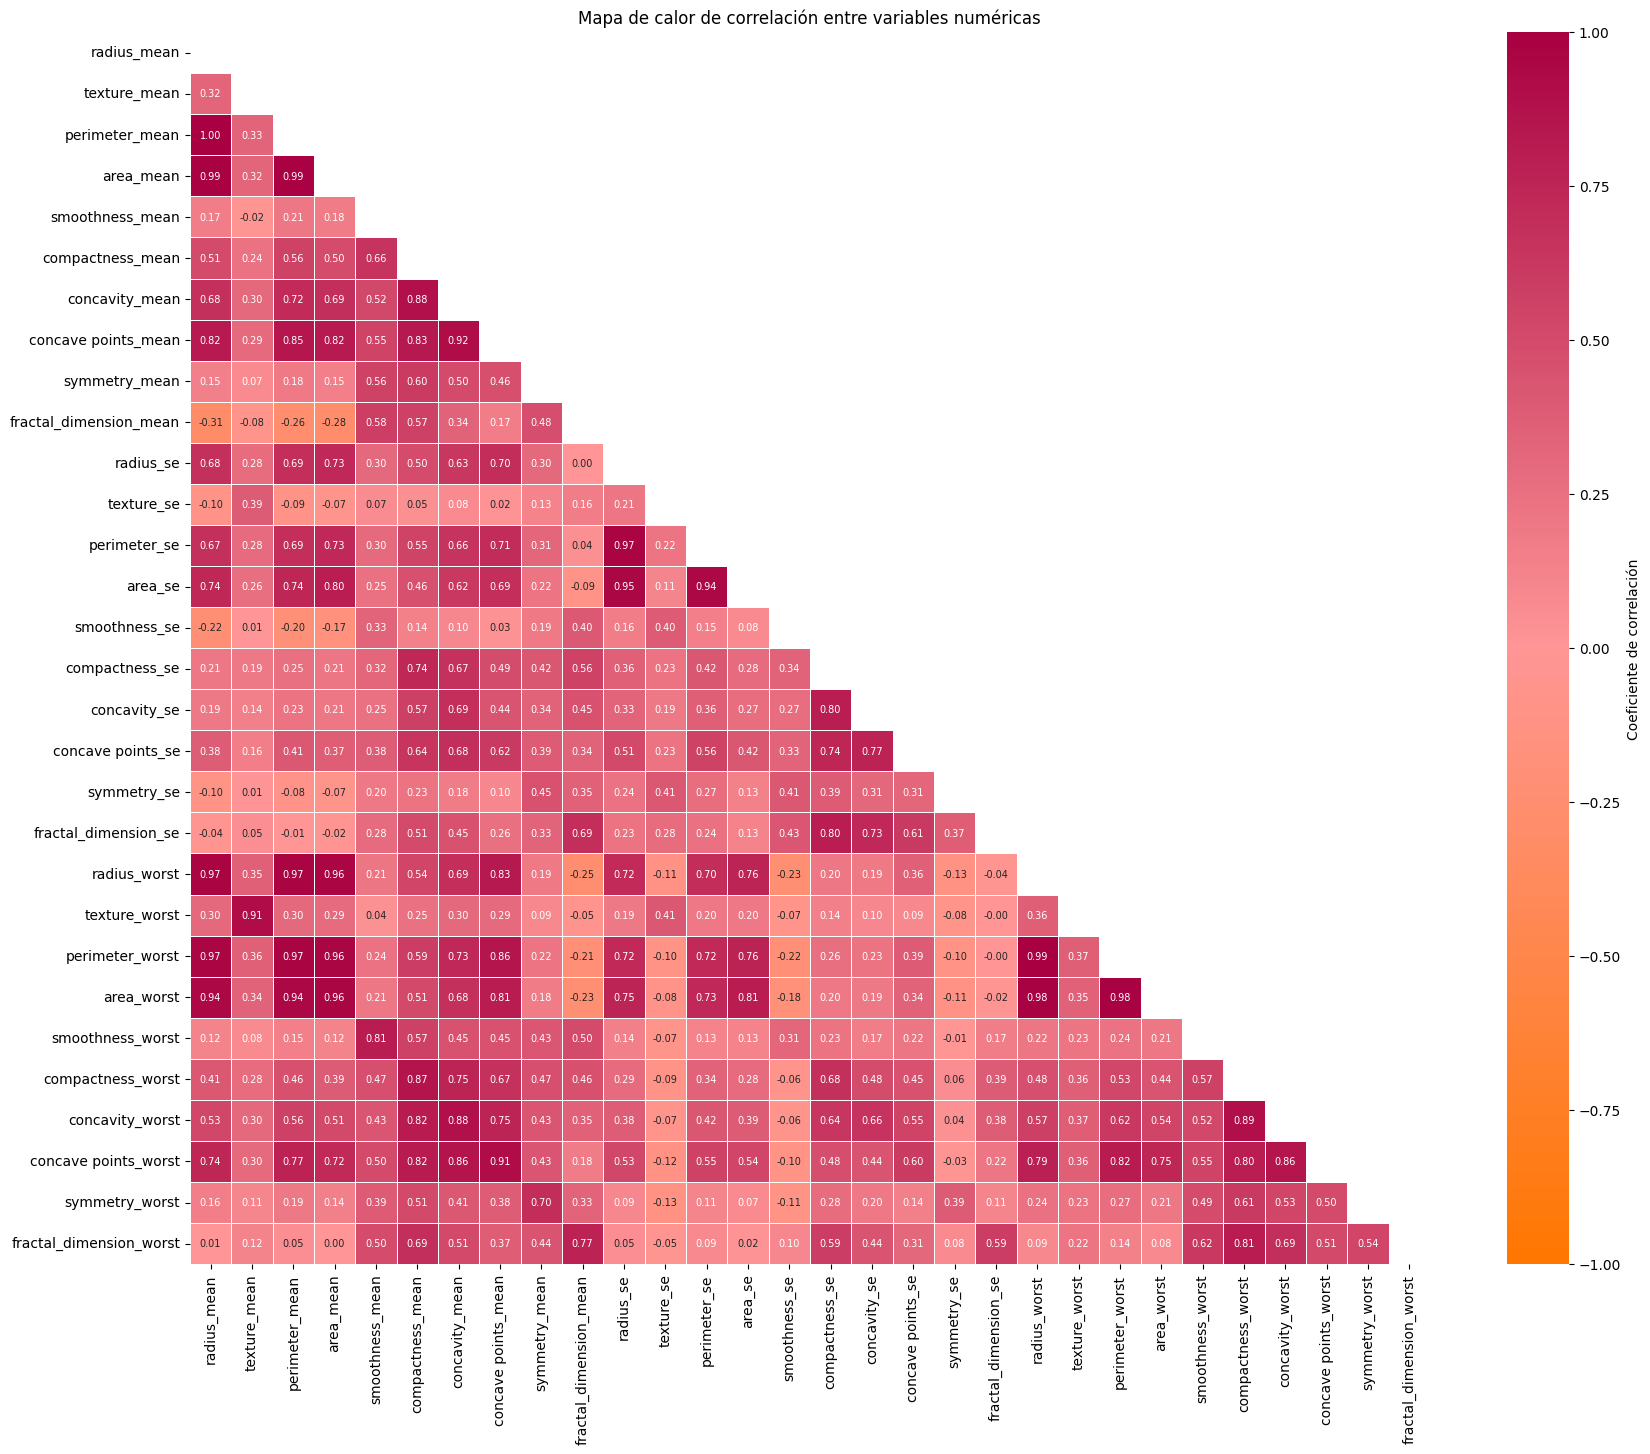

In [17]:
from matplotlib.colors import LinearSegmentedColormap

numeric_df = data_df.select_dtypes(include=[float, int])

#-----------------------------------------------------
# Matriz de correlación entre todas las variables numéricas
corr = numeric_df.corr()

# Oculta el triángulo superior para no repetir valores
mask = np.triu(np.ones_like(corr, dtype=bool))

# Paleta propia: naranja para correlaciones negativas, rosa para valores cercanos a 0 y guinda para las positivas
paleta = LinearSegmentedColormap.from_list('naranja_guinda', ['#FF7700', '#FF9696','#A80041'])

plt.figure(figsize=(20,16))
sns.heatmap(corr, mask=mask, cmap=paleta, vmin=-1, vmax=1, center=0,
            annot=True, fmt='.2f', annot_kws={'size':7},
            linewidths=0.5, cbar_kws={'label':'Coeficiente de correlación'})
plt.title('Mapa de calor de correlación entre variables numéricas')
plt.show()
#-----------------------------------------------------

En esta sección se construye un mapa de calor para medir qué tan relacionadas están las variables numéricas entre sí. La relación se expresa con el coeficiente de correlación, que toma valores entre -1 y 1. Un valor cercano a 1 indica que las dos variables aumentan juntas. Un valor cercano a -1 indica que una aumenta cuando la otra disminuye. Un valor cercano a 0 indica que no hay una relación lineal clara.

Primero se calcula la matriz de correlación con `corr()`. Después se dibuja con `sns.heatmap()`, donde cada casilla muestra el coeficiente de un par de variables y su color indica la fuerza de la relación. Se oculta la mitad superior de la matriz porque repite la información de la mitad inferior.

Este análisis es necesario porque, cuando varias variables predictoras tienen una correlación muy alta entre sí, se presenta multicolinealidad. En ese caso el modelo no puede identificar con claridad el efecto de cada variable sobre el diagnóstico.

En el mapa se observan bloques de correlaciones muy altas y, además de la diagonal principal, una segunda franja de valores altos que corresponde a la relación entre cada variable `_mean` y su correspondiente `_worst` (aproximadamente entre 0.70 y 0.97). Por eso se revisan con especial atención los valores entre las variables `_mean` y `_worst`.

Si te fijas en los valores de correlación entre las variables `_mean` y `_worst` es evidente la multicolinearidad.

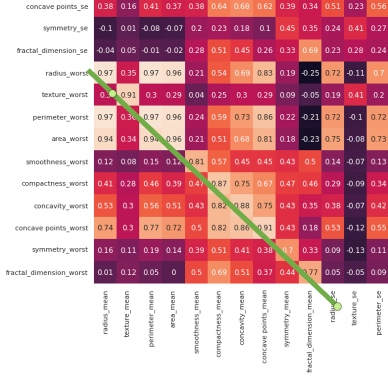

Por ejemplo, la columna `radius_mean` tiene una correlación de 0.97 con la columna `radius_worst`. Esto es algo inevitable, porque las columnas "peores" son esencialmente solo un subconjunto de las columnas "medias".

Para solucionar el problema numérico de la multicolinealidad, tradicionalmente se recurre a eliminar variables o efectuar análisis de componentes principales (PCA) con las `X`’s y usar los componentes como variables independientes en un modelo final.

Conduciremos esta actividad en esos dos sentidos.

# **Parte 2**. Modelo con eliminación de variables altamente correlacionadas  

Elimina las variables altamente correlacionadas:

3a) Ahora que sabes que las variables `_mean` y `_worst` tienen correlación alta, hay que quitar del dataframe un conjunto. Borra las columnas `_worst`.

In [18]:
#-----------------------------------------------------
#Elimine TODAS las columnas _worst
cols_worst = [col for col in data_df.columns if col.endswith('_worst')]
#-----------------------------------------------------

#para borrar las columnas _worst
new_data_df = data_df.drop(columns=cols_worst)

#-----------------------------------------------------
#Convierte new_data_df en Dataframe usando .DataFrame() de la libreria de pandas
new_data_df = pd.DataFrame(new_data_df)
new_data_df
#-----------------------------------------------------

,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,symmetry_mean,...,radius_se,texture_se,perimeter_se,area_se,smoothness_se,compactness_se,concavity_se,concave points_se,symmetry_se,fractal_dimension_se
id,,,,,,,,,,,,,,,,,,,,,
842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.30010,0.14710,0.2419,...,1.0950,0.9053,8.589,153.40,0.006399,0.04904,0.05373,0.01587,0.03003,0.006193
842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.08690,0.07017,0.1812,...,0.5435,0.7339,3.398,74.08,0.005225,0.01308,0.01860,0.01340,0.01389,0.003532
84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.19740,0.12790,0.2069,...,0.7456,0.7869,4.585,94.03,0.006150,0.04006,0.03832,0.02058,0.02250,0.004571
84348301,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.24140,0.10520,0.2597,...,0.4956,1.1560,3.445,27.23,0.009110,0.07458,0.05661,0.01867,0.05963,0.009208
84358402,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.19800,0.10430,0.1809,...,0.7572,0.7813,5.438,94.44,0.011490,0.02461,0.05688,0.01885,0.01756,0.005115
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
926424,M,21.56,22.39,142.00,1479.0,0.11100,0.11590,0.24390,0.13890,0.1726,...,1.1760,1.2560,7.673,158.70,0.010300,0.02891,0.05198,0.02454,0.01114,0.004239
926682,M,20.13,28.25,131.20,1261.0,0.09780,0.10340,0.14400,0.09791,0.1752,...,0.7655,2.4630,5.203,99.04,0.005769,0.02423,0.03950,0.01678,0.01898,0.002498
926954,M,16.60,28.08,108.30,858.1,0.08455,0.10230,0.09251,0.05302,0.1590,...,0.4564,1.0750,3.425,48.55,0.005903,0.03731,0.04730,0.01557,0.01318,0.003892


`drop(columns=...)` crea un nuevo DataFrame, por lo que `data_df` conserva sus 30 variables originales (se necesitan más adelante para el modelo). En `new_data_df` quedan las 20 variables numéricas `_mean` y `_se` más `diagnosis`.

En las graficas de dispersion, los patrones lineales en los diagramas de dispersion se refieren a la relacion entre dos variables que sigue una tendencia aproximadamente en linea recta, ya sea en direccion ascendente o descentende

* **Patron lineal positivo**: Si la linea se inclina hacia arriba (de izquierda a derecha), indica que hay una relacion directa entre las variables: cuando la variable aumenta, la otra tambien lo hace, es decir, CORRELACION POSITIVA

* **Patron lineal negativo**: si la linea se incluna hacia abajo (de izquierda a derecha), indica quue cuando una variable aumenta, la otra disminuye, es decir, CORRELACION NEGATIVA

* **Patron lineal perfecto**, si los puntos siguen una linea recta perfecta, la relacion entre las variables es exactamente lineal, sin desviaciones.


3b. Entre las variables `_mean`, identifica patrones lineales con diagramas de dispersión usando:

    sns.pairplot(data=nuevo_df[['radius_mean',
        'texture_mean',
        'perimeter_mean',
        'area_mean',
        'smoothness_mean',
        'compactness_mean',
        'concavity_mean',
        'concave points_mean',
        'symmetry_mean',
        'fractal_dimension_mean']])

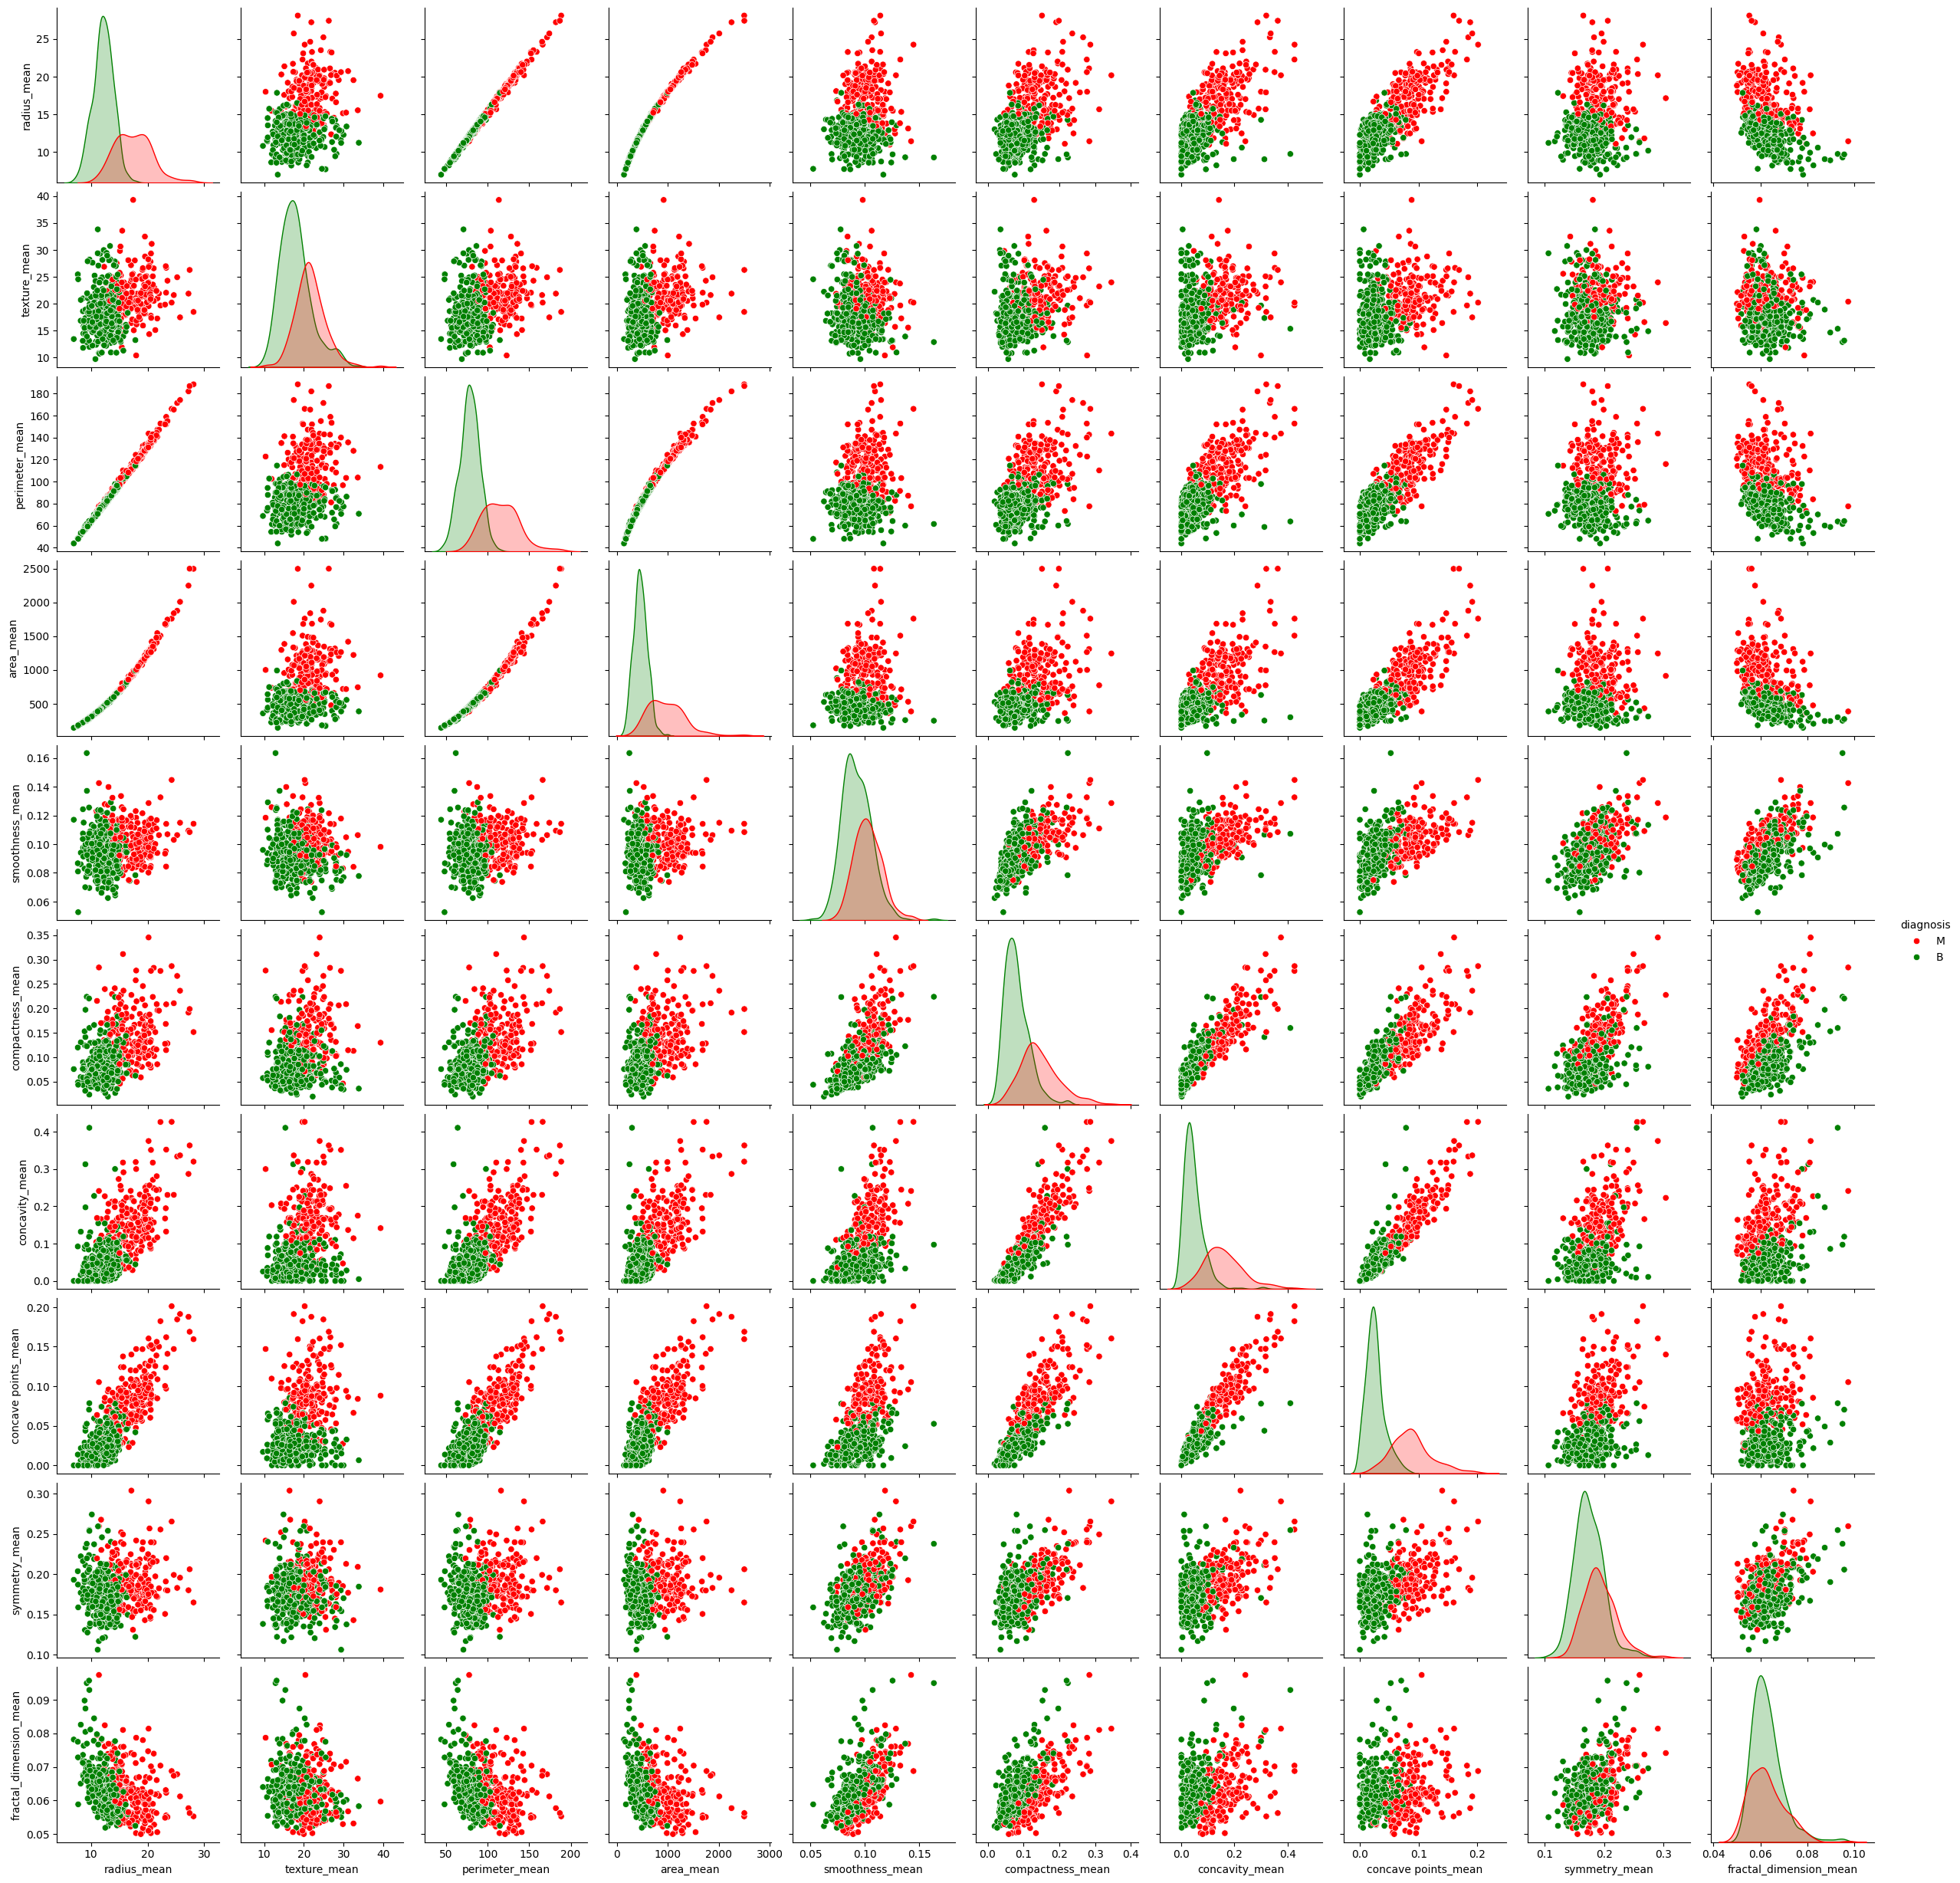

In [19]:
#-----------------------------------------------------
# Se agrega diagnosis solo para colorear los puntos: benigno (verde) y maligno (rojo)
sns.pairplot(data=new_data_df[['radius_mean',
    'texture_mean',
    'perimeter_mean',
    'area_mean',
    'smoothness_mean',
    'compactness_mean',
    'concavity_mean',
    'concave points_mean',
    'symmetry_mean',
    'fractal_dimension_mean',
    'diagnosis']],
    hue='diagnosis', palette={'B':'green','M':'red'})
plt.show()
#-----------------------------------------------------

De la matriz podrás observar relaciones lineales bastante evidentes entre:


*   `radius_mean`, `perimeter_mean` y `area_mean`
*   `compactness_mean`, `concavity_mean`, `concave_points_mean`

Sabemos que el perímetro y el área de un círculo, se calculan a partir del radio. Entonces, la relación entre las primeras tres variables es muy clara para nosotros.

En las gráficas de dispersión se observa una relación muy fuerte entre `radius_mean`, `perimeter_mean` y `area_mean`: sus puntos forman casi una línea recta, es decir, un patrón lineal positivo casi perfecto en el que, cuando una variable aumenta, las otras también lo hacen de forma constante.

Las variables `compactness_mean`, `concavity_mean` y `concave points_mean` también presentan un patrón lineal positivo marcado, aunque más disperso. Al colorear por diagnóstico se aprecia además que los casos malignos (rojo) tienden a valores más altos de tamaño y de concavidad.

3c) Elabora otro mapa de calor confirmar con los valores de correlación.

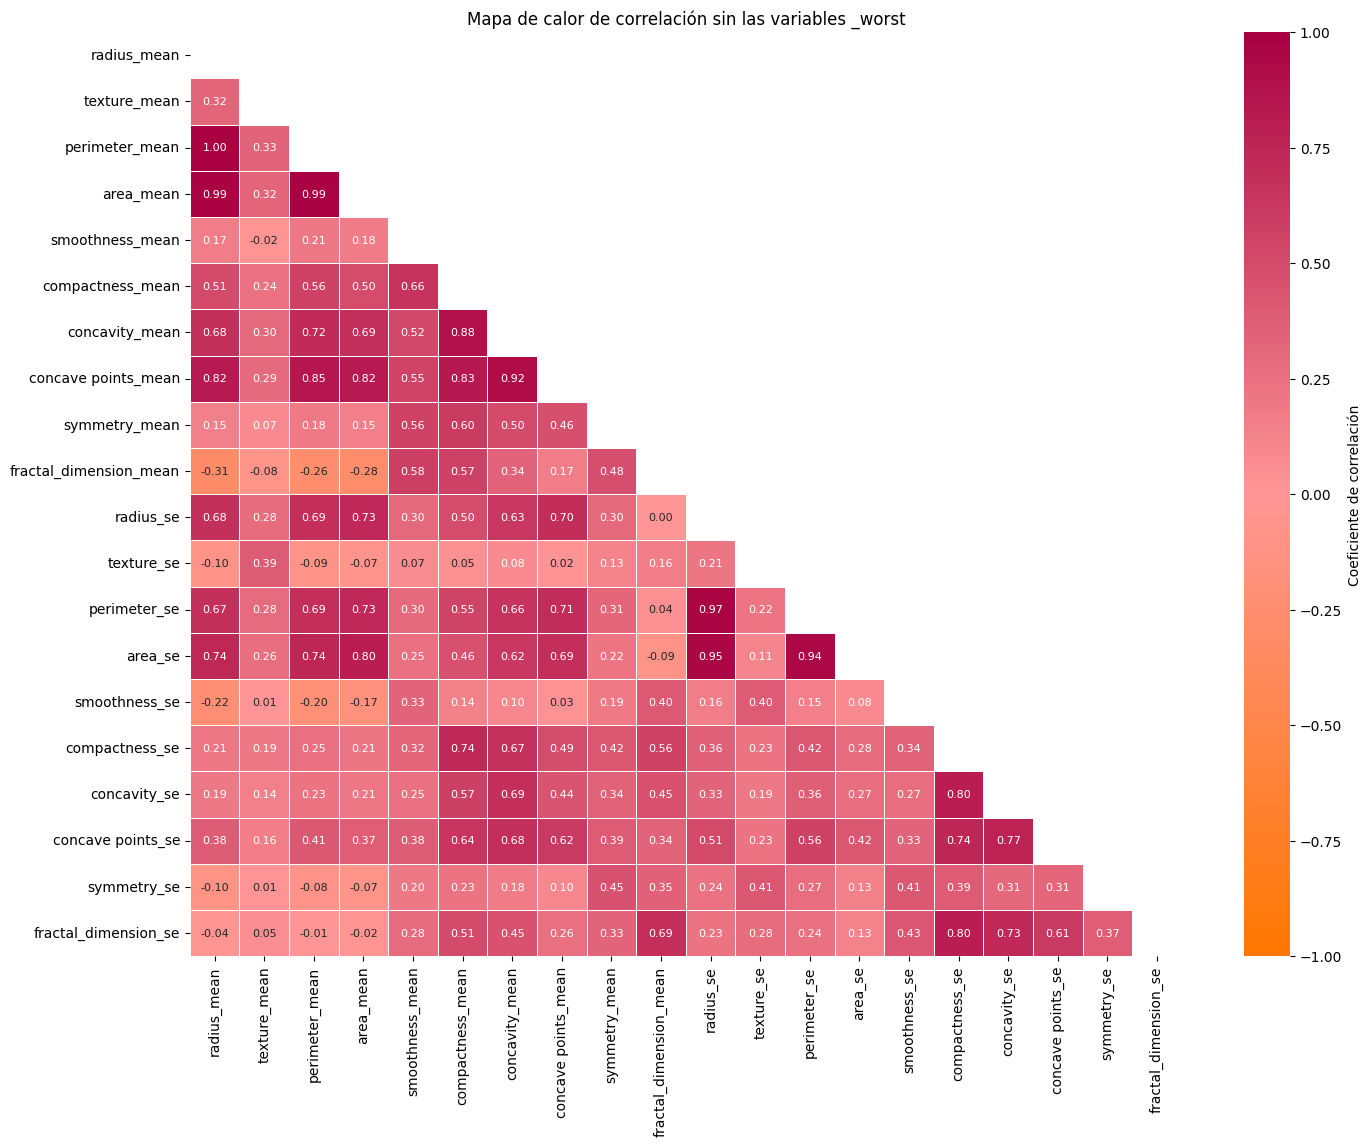

In [20]:
#-----------------------------------------------------
# Solo variables numericas, porque diagnosis es texto
numeric_df2 = new_data_df.select_dtypes(include=[float, int])

# Matriz de correlación
corr2 = numeric_df2.corr()

# Oculta el triángulo superior para no repetir valores
mask2 = np.triu(np.ones_like(corr2, dtype=bool))

plt.figure(figsize=(16,12))
sns.heatmap(corr2, mask=mask2, cmap=paleta, vmin=-1, vmax=1, center=0,
            annot=True, fmt='.2f', annot_kws={'size':8},
            linewidths=0.5, cbar_kws={'label':'Coeficiente de correlación'})
plt.title('Mapa de calor de correlación sin las variables _worst')
plt.show()
#-----------------------------------------------------

El mapa muestra el coeficiente de correlación de cada par de variables. Los valores cercanos a 1 indican una relación positiva muy fuerte. Los resultados confirman que `radius_mean`, `perimeter_mean` y `area_mean` están casi perfectamente relacionadas (correlaciones de 0.99 a 1.00), lo cual tiene sentido porque el perímetro y el área se calculan a partir del radio. También confirman una relación alta entre `compactness_mean`, `concavity_mean` y `concave points_mean` (entre 0.83 y 0.92 aproximadamente).

Estas variables aportan información muy parecida al modelo. Por esa razón en el siguiente paso se conserva una sola variable de cada grupo y se eliminan las demás.

3d) Después de observar los valores, nos quedaremos con sólo una variable de cada trío: `radius_mean` y `compactness_mean`. Elimina las restantes, no sólo del conjunto `_mean`, sino también de `_se`.

In [21]:
#Escriba TODAS las columnas que seran eliminadas (las 8 de los grupos _mean y _se)
columnas_a_eliminar_3d = ['perimeter_mean', 'area_mean', 'concavity_mean', 'concave points_mean',
                          'perimeter_se', 'area_se', 'concavity_se', 'concave points_se']

#Convierte new_data_df en Dataframe usando .DataFrame() de la libreria de pandas
new_data_df = pd.DataFrame(new_data_df.drop(columns=columnas_a_eliminar_3d))
new_data_df

,diagnosis,radius_mean,texture_mean,smoothness_mean,compactness_mean,symmetry_mean,fractal_dimension_mean,radius_se,texture_se,smoothness_se,compactness_se,symmetry_se,fractal_dimension_se
id,,,,,,,,,,,,,
842302,M,17.99,10.38,0.11840,0.27760,0.2419,0.07871,1.0950,0.9053,0.006399,0.04904,0.03003,0.006193
842517,M,20.57,17.77,0.08474,0.07864,0.1812,0.05667,0.5435,0.7339,0.005225,0.01308,0.01389,0.003532
84300903,M,19.69,21.25,0.10960,0.15990,0.2069,0.05999,0.7456,0.7869,0.006150,0.04006,0.02250,0.004571
84348301,M,11.42,20.38,0.14250,0.28390,0.2597,0.09744,0.4956,1.1560,0.009110,0.07458,0.05963,0.009208
84358402,M,20.29,14.34,0.10030,0.13280,0.1809,0.05883,0.7572,0.7813,0.011490,0.02461,0.01756,0.005115
...,...,...,...,...,...,...,...,...,...,...,...,...,...
926424,M,21.56,22.39,0.11100,0.11590,0.1726,0.05623,1.1760,1.2560,0.010300,0.02891,0.01114,0.004239
926682,M,20.13,28.25,0.09780,0.10340,0.1752,0.05533,0.7655,2.4630,0.005769,0.02423,0.01898,0.002498
926954,M,16.60,28.08,0.08455,0.10230,0.1590,0.05648,0.4564,1.0750,0.005903,0.03731,0.01318,0.003892


Después de eliminar estas 8 variables quedan 12 predictores numéricos: `radius_mean`, `texture_mean`, `smoothness_mean`, `compactness_mean`, `symmetry_mean`, `fractal_dimension_mean` y sus equivalentes `_se` (`radius_se`, `texture_se`, `smoothness_se`, `compactness_se`, `symmetry_se`, `fractal_dimension_se`), además de la columna `diagnosis`.

Observa la distribución de las variables resultantes (deben ser 12, sin contar la columna de indice):

4a) Utilizando histogramas. Guarda en una variable (`skew_cols`) las que tengan marcado sesgo positivo. Para dar seguridad a tu selección, elige aquellas cuyo resultado de aplicar la función `skew()` sea mayor a 1.

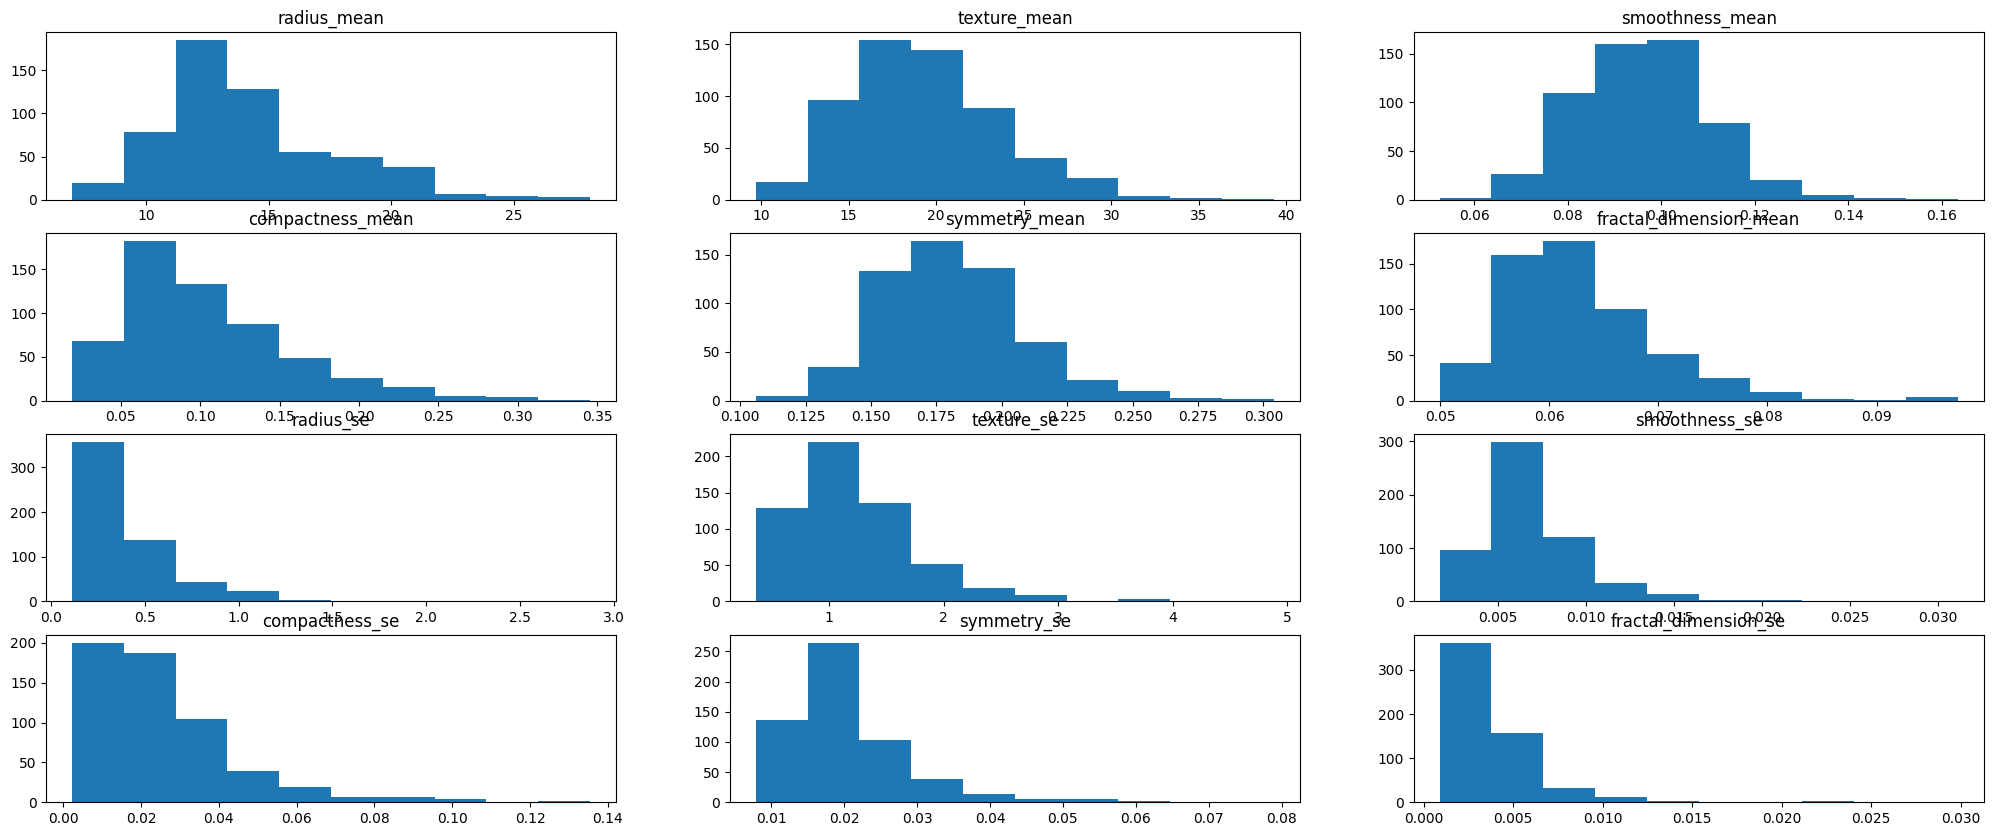

In [22]:
#EXPLICA CADA LINEA DE CODIGO

# Crea un DataFrame vacío donde se guardarán las variables con sesgo positivo
skew_cols_df=pd.DataFrame()

# Crea una figura con 12 espacios para gráficas, organizados en 4 filas y 3 columnas
# El 25 es el ancho de la figura y el 10 es la altura
fig, axes =plt.subplots(4,3, figsize=(25,10))

# Convierte la matriz de espacios 4x3 en una lista simple de 12 (ravel), para poder recorrerla con un ciclo
axes = axes.ravel()

# Guarda en una lista los nombres de las columnas numéricas de new_data_df
# (aquí new_data_df ya solo tiene las 12 variables que se conservaron, una por cada espacio de la figura)
num_cols = new_data_df.select_dtypes(include=np.number).columns.tolist()

# Recorre al mismo tiempo cada columna y un espacio de gráfica, uno por cada variable
for col, ax in zip (num_cols, axes):

  # Dibuja el histograma de la variable en su espacio
  ax.hist(new_data_df[col])

  # Pone el nombre de la variable como título y quita el texto del eje x
  ax.set(title = f'{col}', xlabel=None)

  # skew() mide qué tan asimétrica es la distribución
  # Si el resultado es mayor a 1, la variable tiene sesgo positivo y se copia a skew_cols_df
  if new_data_df[col].skew()>1 : skew_cols_df[col] =new_data_df[col]

# Guarda solo los nombres de las variables con sesgo positivo
skew_cols = skew_cols_df.columns.values

Se observa la distribución de las 12 variables numéricas que quedaron después de eliminar las columnas correlacionadas. Para esto se dibuja un histograma por variable, que muestra con qué frecuencia aparece cada rango de valores.

Además se mide el sesgo de cada variable con `skew()`. El sesgo indica si la distribución es simétrica o si tiene una cola larga hacia un lado. Un sesgo positivo significa que la mayoría de los datos son pequeños y que existen pocos valores muy grandes que alargan la cola hacia la derecha.

Se establece como criterio que una variable tiene un sesgo marcado cuando el resultado de `skew()` es mayor a 1. Los nombres de esas variables se guardan en `skew_cols`. Esta lista se utiliza más adelante para aplicarles una transformación que reduzca el sesgo.

In [23]:
skew_cols

array(['compactness_mean', 'fractal_dimension_mean', 'radius_se',
       'texture_se', 'smoothness_se', 'compactness_se', 'symmetry_se',
       'fractal_dimension_se'], dtype=object)

4b) Dibujando box plots de todas las variables. Guarda en una variable (`scale_cols`) aquellas que se encuentren en el intervalo [0,1]

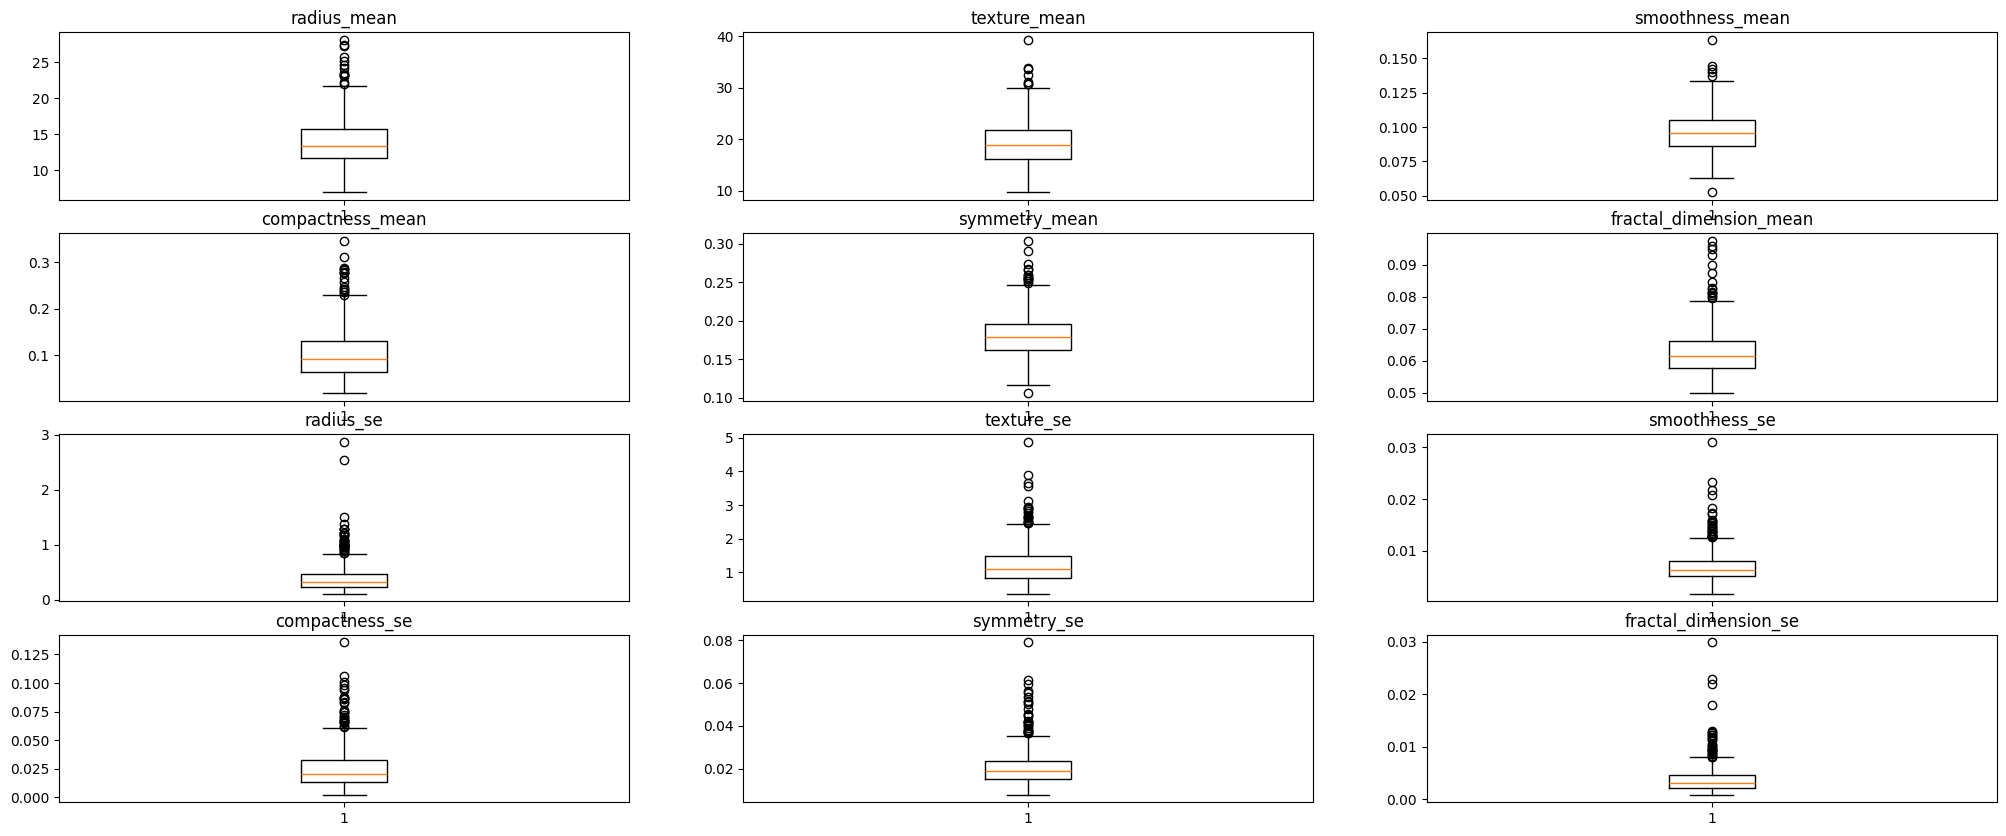

In [24]:
scale_cols_df=pd.DataFrame()
fig, axes = plt.subplots(4,3, figsize=(25,10))
axes = axes.ravel()

#-----------------------------------------------------
for col, ax in zip(num_cols, axes):

  # Dibuja el diagrama de caja de la variable
  ax.boxplot(new_data_df[col])
  ax.set_title(f'{col}')

  # Se guardan las variables que SÍ están contenidas en el intervalo [0,1]:
  # las que tienen un máximo menor a 1 y un mínimo mayor o igual a 0
  if new_data_df[col].max() < 1 and new_data_df[col].min() >= 0:
    scale_cols_df[col] = new_data_df[col]
#-----------------------------------------------------

scale_cols = scale_cols_df.columns.values

Aquí se dibuja un diagrama de caja por cada una de las 12 variables numéricas. Este diagrama muestra el rango de valores de la variable y permite ver en qué escala se encuentra. La caja contiene la mitad central de los datos y la línea dentro de ella marca la mediana. Los puntos fuera de los bordes representan valores poco comunes.

Además se revisa si cada variable está dentro del intervalo de 0 a 1. Las variables cuyo valor máximo es menor a 1 y cuyo valor mínimo es mayor o igual a 0 (es decir, las que **sí** están contenidas en ese intervalo) se guardan en la lista `scale_cols`. En este caso son `smoothness_mean`, `compactness_mean`, `symmetry_mean`, `fractal_dimension_mean` y sus equivalentes `_se`.

Más adelante se aplicará el escalamiento `MinMax` a las variables de esta lista. Con este criterio quedan fuera del escalamiento `radius_mean`, `texture_mean`, `radius_se` y `texture_se`, cuyos valores superan 1.

In [25]:
scale_cols

array(['smoothness_mean', 'compactness_mean', 'symmetry_mean',
       'fractal_dimension_mean', 'smoothness_se', 'compactness_se',
       'symmetry_se', 'fractal_dimension_se'], dtype=object)

Con todo el análisis anterior, estamos listos para generar un modelo *baseline* denominado `logr_model`. Para ello:

5a) Vuelve a leer el contenido del archivo, haz que el `id` sea el índice y separa las variables del dataframe: en `X` coloca los predictores y en `y` la variable de respuesta o salida (`diagnosis`). Divide el conjunto en entrenamiento y prueba (80:20) considerando el parámetro `random_state` con el valor de 1.

In [26]:
data_df = pd.read_csv(RUTA_CSV)

#AGREGA LINEA DE CODIGO PARA CONVERTIR COLUMNA "ID" EN INDICE
data_df.set_index('id', inplace=True)

In [27]:
X = data_df.copy() #Se crea copia del df
#-----------------------------------------------------
#                                  COMPLETA CODIGO
# se elimina variable Categorica "diagnosis" de (X), debido a se sera utilizada como variable de salida (y)
#-----------------------------------------------------
#Especifique la columna que desea eliminar
#Utilice el parametro axis=1, permitira eliminar la columna
#Guarde los cambios agregando el parametro inplace=True

X.drop('diagnosis', axis=1, inplace=True) #Caracteristica / variable Entrada

y = data_df['diagnosis'] #Objetivo /Variable salida

In [28]:
#Libreria necesaria para realizar la particion del conjunto de datos
from sklearn.model_selection import train_test_split

# Se divide el conjunto en entrenamiento y prueba (80:20), es decir, 80% para Entrenamiento (train) y 20% para Prueba (test)
Xtrain, Xtest, ytrain, ytest = train_test_split(X, y, test_size=0.2, random_state=1)

Aquí se prepara la información para construir un primer modelo, llamado `logr_model`. Primero se vuelve a leer el archivo original para trabajar con todas las variables y se convierte la columna `id` en el índice.

Después se separan los datos en dos partes. En `X` se guardan las variables predictoras, que son las medidas de las células. En `y` se guarda la variable de respuesta, que es `diagnosis`. Para esto se elimina la columna `diagnosis` de `X` con `drop()`, usando `axis=1` para indicar que se trata de una columna.

Por último se divide el conjunto con `train_test_split()`. El 80% de los casos se usa para entrenar el modelo y el 20% restante se reserva para evaluarlo con datos que no vio durante el entrenamiento. El valor `random_state=1` fija la forma en que se reparten los casos, por lo que la división es la misma cada vez que se ejecuta el código.

5b) Prepara un transformador, denominado `preprocessing`, para borrar las columnas altamente correlacionadas (las 18 variables que se determinaron en los ejercicios previos) Asegúrate de incluir el parámetro `remainder='passthrough'` para mantener el resto de las variables.

In [29]:
#EXPLIQUE CADA LINEA DE CODIGO

# Lista con los nombres de las 18 columnas que se van a eliminar:
# las 10 columnas _worst (cols_worst, paso 3a) y las 8 variables _mean y _se descartadas en el paso 3d
columnas_a_eliminar = cols_worst + columnas_a_eliminar_3d
print(len(columnas_a_eliminar), 'columnas a eliminar')

# ColumnTransformer aplica una operación distinta a cada grupo de columnas
preprocessing = ColumnTransformer([

    # Cada paso tiene tres partes: un nombre, la operación y las columnas donde se aplica.
    # 'num' es solo el nombre del paso, 'drop' indica que las columnas se eliminan
    # y columnas_a_eliminar es la lista de columnas afectadas
    ('num', 'drop', columnas_a_eliminar)]

   # remainder='passthrough' deja pasar sin cambios todas las columnas que no se mencionaron.
   # Sin este parámetro, el transformador también eliminaría las 12 variables restantes
   ,remainder='passthrough')

18 columnas a eliminar


5c) Entrena el modelo `logr_model` con el transformador `preprocessing` y  regresión logística.

Como la salida `y` está en términos de las etiquetas `'B'` y `'M'`, en lugar de 0 y 1, para evaluar el modelo en el conjunto de prueba deberás especificar la clase positiva. En el caso de la matriz de confusión, indica el orden de las etiquetas con `labels=['B','M']`, porque `'B'` es la clase negativa (ésta se especifica primero) y `'M'` la positiva. Para las métricas de *recall* y *precision*, utiliza el parámetro `pos_label='M'`. Como *accuracy* ocupa la suma de ambas clases y el total de las observaciones, no requiere ninguna especificación. Si quisieras omitir estos parámetros, tendrías que sustituir `'B'` por 0 y `'M'` por 1, previo a la construcción del modelo.

In [30]:
#EXPLIQUE CADA LINEA DE CODIGO

# make_pipeline une varios pasos en un solo flujo. Primero se aplica preprocessing,
# que elimina las 18 columnas correlacionadas, y después se entrena la regresión logística
logr_model=make_pipeline(preprocessing, LogisticRegression())

# fit() entrena el modelo con el 80% de los datos, que son Xtrain y sus diagnósticos reales en ytrain
logr_model.fit(Xtrain,ytrain)

# predict() usa el modelo entrenado para predecir el diagnóstico de los casos de prueba.
# Estos casos no se usaron durante el entrenamiento
predictions=logr_model.predict(Xtest)

# La matriz de confusión compara los diagnósticos reales con los predichos.
# labels=['B','M'] define el orden de filas y columnas, donde B es la clase negativa y M la positiva
print('matriz de confusion 1:\n',confusion_matrix(ytest,predictions,labels=['B','M']))

# recall: de todos los casos que realmente eran malignos, qué proporción detectó el modelo.
# pos_label='M' indica que M es la clase positiva
print('recall    :\t',recall_score(ytest,predictions,pos_label='M'))

# precision: de todos los casos que el modelo predijo como malignos, qué proporción lo era realmente
print('precision :\t',precision_score(ytest,predictions,pos_label='M'))

# accuracy: proporción de predicciones correctas sobre el total de casos de prueba
print('accuracy  :\t',accuracy_score(ytest,predictions))

matriz de confusion 1:
 [[68  4]
 [10 32]]
recall    :	 0.7619047619047619
precision :	 0.8888888888888888
accuracy  :	 0.8771929824561403


## **Interpretación de los resultados obtenidos de la matriz de confusión y métricas (Modelo 1)**

|  | Predicho B | Predicho M |
|----------|--------------|--------------|
|**Real B**| 68 | 4 |
|**Real M**| 10 | 32 |

**Matriz de confusión**

* **Verdaderos negativos (68):** casos realmente benignos (`B`) que el modelo clasificó correctamente como benignos.
* **Falsos positivos (4):** casos benignos que el modelo predijo erróneamente como malignos (`M`). En medicina representa una falsa alarma.
* **Falsos negativos (10):** casos realmente malignos que el modelo clasificó como benignos. Es el error más crítico en un diagnóstico, ya que un paciente enfermo no es detectado a tiempo.
* **Verdaderos positivos (32):** casos realmente malignos que el modelo detectó y clasificó correctamente.

**Métricas**

* **Recall = 0.76:** el modelo detectó 32 de los 42 casos que realmente eran malignos, es decir, el 76% de ellos. Para un problema médico es un nivel bajo, porque deja sin detectar 10 casos graves.
* **Precisión = 0.89:** de los 36 casos que el modelo predijo como malignos, 32 lo eran realmente (89%). El modelo genera pocas falsas alarmas.
* **Exactitud (accuracy) = 0.88:** corresponde a 100 predicciones correctas sobre los 114 casos de prueba.

La precisión es mayor que el recall. Esto indica que el modelo se equivoca con mayor frecuencia al dejar pasar casos malignos que al señalar como malignos casos benignos. Como el falso negativo corresponde a un caso maligno sin detectar, el recall es la métrica que más interesa mejorar. Estos valores se toman como punto de comparación para el modelo 2, que incluye transformación y escalamiento de las variables.

Para generar un modelo `logr_model2` con transformación y escalamiento:

6a) Modifica el transformador anterior para, además del borrado de las columnas correlacionadas, aplicar la raíz cuadrada a los predictores con sesgo (previamente almacenados en `skew_cols`) y escalamiento *MinMax* a los predictores con escala mayor a 1 (previamente almacenados en `scale_cols`) Como no todos los predictores serán eliminados o transformados, asegúrate de incluir el parámetro `remainder='passthrough'`

In [31]:
#EXPLIQUE CADA LINEA DE CODIGO

# Crea un segundo transformador que, además de eliminar columnas, transforma y escala otras
preprocessing2 = ColumnTransformer([

    # Elimina las 18 columnas correlacionadas, igual que en el primer modelo
    ('num0','drop', columnas_a_eliminar),

    # Aplica la raíz cuadrada a las variables con sesgo positivo guardadas en skew_cols.
    # FunctionTransformer convierte la función np.sqrt en un paso del transformador.
    # La raíz cuadrada acorta la cola de valores muy grandes y hace la distribución más simétrica
    ('num1',FunctionTransformer(np.sqrt),skew_cols),

    # Aplica MinMaxScaler a las variables guardadas en scale_cols.
    # Este escalamiento lleva los valores al intervalo de 0 a 1 para que todas las variables
    # tengan una escala parecida
    ('num2',MinMaxScaler(),scale_cols)

  # Las columnas que no aparecen en ningún paso se conservan sin cambios
  ],remainder='passthrough')

In [32]:
# Revisión de las listas: ¿alguna variable aparece en las dos?
print('skew_cols :', skew_cols)
print('scale_cols:', scale_cols)
print('En ambas  :', np.intersect1d(skew_cols, scale_cols))

skew_cols : ['compactness_mean' 'fractal_dimension_mean' 'radius_se' 'texture_se'
 'smoothness_se' 'compactness_se' 'symmetry_se' 'fractal_dimension_se']
scale_cols: ['smoothness_mean' 'compactness_mean' 'symmetry_mean'
 'fractal_dimension_mean' 'smoothness_se' 'compactness_se' 'symmetry_se'
 'fractal_dimension_se']
En ambas  : ['compactness_mean' 'compactness_se' 'fractal_dimension_mean'
 'fractal_dimension_se' 'smoothness_se' 'symmetry_se']


Al revisar las listas de variables se observa que seis variables (`compactness_mean`, `fractal_dimension_mean`, `smoothness_se`, `compactness_se`, `symmetry_se` y `fractal_dimension_se`) aparecen tanto en `skew_cols` como en `scale_cols`. Esto significa que el transformador `preprocessing2` las procesa dos veces, una con la raíz cuadrada y otra con el escalamiento `MinMax`, de forma independiente. Como resultado, el modelo recibe dos versiones de cada una de estas variables.

6b) Entrena el modelo `logr_model2` con regresión logística, aplicando previamente el transformador modificado. Evalúa el modelo en el conjunto de prueba con las mismas métricas.

In [33]:
# Pipeline con el transformador modificado y la regresión logística
logr_model2 = make_pipeline(preprocessing2, LogisticRegression())

# Entrena el modelo con el 80% de los datos
logr_model2.fit(Xtrain, ytrain)

# Predice el diagnóstico de los casos de prueba
predictions2 = logr_model2.predict(Xtest)

# Evalúa con las mismas métricas que el modelo 1
print('matriz de confusion 2:\n', confusion_matrix(ytest, predictions2, labels=['B','M']))
print('recall    :\t', recall_score(ytest, predictions2, pos_label='M'))
print('precision :\t', precision_score(ytest, predictions2, pos_label='M'))
print('accuracy  :\t', accuracy_score(ytest, predictions2))

matriz de confusion 2:
 [[68  4]
 [ 7 35]]
recall    :	 0.8333333333333334
precision :	 0.8974358974358975
accuracy  :	 0.9035087719298246


## **Interpretación de los resultados obtenidos de la matriz de confusión y métricas (Modelo 2)**

|  | Predicho B | Predicho M |
|----------|--------------|--------------|
|**Real B**| 68 | 4 |
|**Real M**| 7 | 35 |

**Matriz de confusión**

* **Verdaderos negativos (68):** casos benignos clasificados correctamente como benignos.
* **Falsos positivos (4):** casos benignos que el modelo predijo como malignos (falsas alarmas).
* **Falsos negativos (7):** casos malignos que el modelo clasificó como benignos y quedaron sin detectar.
* **Verdaderos positivos (35):** casos malignos detectados correctamente.

**Métricas**

* **Recall = 0.83:** el modelo detectó 35 de los 42 casos realmente malignos (83%).
* **Precisión = 0.90:** de los 39 casos que predijo como malignos, 35 lo eran realmente (aprox. 90%).
* **Exactitud (accuracy) = 0.90:** 103 predicciones correctas sobre los 114 casos de prueba.

**Comparación con el modelo 1**

| Medida | Modelo 1 | Modelo 2 |
|----------|--------------|--------------|
|**Verdaderos negativos**| 68 | 68 |
|**Falsos positivos**| 4 | 4 |
|**Falsos negativos**| 10 | 7 |
|**Verdaderos positivos**| 32 | 35 |
|**Recall**| 0.76 | 0.83 |
|**Precisión**| 0.89 | 0.90 |
|**Exactitud**| 0.88 | 0.90 |

En comparación con el modelo 1, el número de falsas alarmas se mantuvo en 4, pero los falsos negativos bajaron de 10 a 7: el modelo 2 detecta tres casos malignos más. Por eso el recall subió de 0.76 a 0.83, que es la métrica que más interesaba mejorar en un diagnóstico. La precisión (de 0.89 a 0.90) y la exactitud (de 0.88 a 0.90) también aumentaron ligeramente.

## **Conclusión de la práctica**

En esta práctica se realizó un análisis exploratorio del conjunto de datos y se construyeron dos modelos de regresión logística para clasificar tumores como benignos o malignos.

El análisis exploratorio mostró que las 569 observaciones están completas (sin valores faltantes) y que hay más casos benignos (357) que malignos (212). También mostró que las variables `_mean`, `_se` y `_worst` miden las mismas características y presentan correlaciones altas entre sí (por ejemplo, el radio, el perímetro y el área), lo cual indica multicolinealidad: básicamente se le estaría dando al modelo información repetida. Para reducirla se eliminaron 18 variables y se conservaron 12 predictores.

El **modelo 1** (baseline) se entrenó solo con la eliminación de las variables correlacionadas y obtuvo un recall de 0.76, una precisión de 0.89 y una exactitud de 0.88. El **modelo 2** incorporó además la raíz cuadrada en las 8 variables con sesgo positivo y el escalamiento MinMax en las 8 variables que ya estaban dentro del intervalo [0,1]. Este modelo obtuvo un recall de 0.83, una precisión de 0.90 y una exactitud de 0.90.

Los resultados muestran que la transformación y el escalamiento mejoraron el modelo: los falsos negativos bajaron de 10 a 7 (tres casos malignos más detectados), mientras que los falsos positivos se mantuvieron en 4. Esto es importante en un diagnóstico, porque el falso negativo representa un caso maligno sin detectar, y el recall fue la métrica con la mejora más notable.

Hay que tomar en cuenta que los resultados provienen de una sola división de los datos con 114 casos de prueba (42 malignos), por lo que un caso más o menos modifica las métricas de forma visible. Además, seis variables (`compactness_mean`, `fractal_dimension_mean`, `smoothness_se`, `compactness_se`, `symmetry_se` y `fractal_dimension_se`) recibieron las dos transformaciones de manera independiente, de modo que el modelo 2 incluye dos versiones de cada una.

En resumen, con esta práctica quedó claro que no conviene meter los datos directo a un modelo sin revisarlos antes: la clave de un buen modelo no es solo el algoritmo que se elija, sino el tiempo que se dedique a explorar, limpiar, transformar y escalar los datos, y a elegir la métrica que realmente importa para el problema (en este caso, no dejar pasar casos malignos).